# Предсказание калорийности блюд

## Этап 3. Обучение модели

## 1. Подготовка окружения

In [3]:
![ -d Nutrition ] || git clone https://github.com/andr3w13/Nutrition.git
%cd Nutrition
%pip install -q -r requirements.txt

Cloning into 'Nutrition'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 22 (delta 2), reused 22 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 1.58 MiB | 4.12 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/Nutrition


In [ ]:
import os
import shutil
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import pandas as pd
import torch

GDRIVE_FILE_ID = "19cIhxmvhRVpRqGHnBCbxLEfEZ51jvsTG"
ARCHIVE = Path("nutrition.zip")
DATA_DIR = Path("data")

if not (DATA_DIR / "dish.csv").exists():
    if not ARCHIVE.exists():
        gdown.download(id=GDRIVE_FILE_ID, output=str(ARCHIVE), quiet=False)
    with zipfile.ZipFile(ARCHIVE) as zf:
        zf.extractall(".")

## 2. Обучение

In [ ]:
from scripts.config import Config

In [7]:
from scripts.utils import train

model, history = train(Config)

Устройство cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Эпоха 1/20 | train loss 110.78 | val MAE 104.67 | val RMSE 157.46
Эпоха 2/20 | train loss 86.36 | val MAE 73.22 | val RMSE 109.60
Эпоха 3/20 | train loss 77.68 | val MAE 68.17 | val RMSE 102.74
Эпоха 4/20 | train loss 70.83 | val MAE 75.55 | val RMSE 109.01
Эпоха 5/20 | train loss 66.78 | val MAE 65.96 | val RMSE 100.81
Эпоха 6/20 | train loss 64.56 | val MAE 67.25 | val RMSE 105.23
Эпоха 7/20 | train loss 62.55 | val MAE 56.01 | val RMSE 87.62
Эпоха 8/20 | train loss 58.28 | val MAE 63.93 | val RMSE 86.69
Эпоха 9/20 | train loss 57.52 | val MAE 56.66 | val RMSE 87.88
Эпоха 10/20 | train loss 57.59 | val MAE 60.70 | val RMSE 90.44
Эпоха 11/20 | train loss 55.29 | val MAE 53.75 | val RMSE 79.34
Эпоха 12/20 | train loss 53.45 | val MAE 57.11 | val RMSE 82.70
Эпоха 13/20 | train loss 51.67 | val MAE 50.04 | val RMSE 78.63
Эпоха 14/20 | train loss 50.46 | val MAE 54.68 | val RMSE 88.08
Эпоха 15/20 | train loss 51.66 | val MAE 54.32 | val RMSE 89.40
Эпоха 16/20 | train loss 49.02 | val MAE 

In [8]:
print(model.classifier)

Sequential(
  (0): Linear(in_features=513, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=256, out_features=1, bias=True)
)


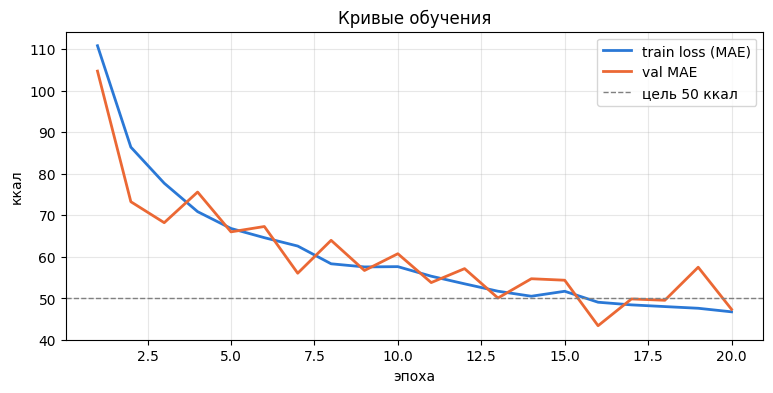

,epoch,train_loss,val_mae,val_rmse
0,1,110.78,104.67,157.46
1,2,86.36,73.22,109.60
2,3,77.68,68.17,102.74
3,4,70.83,75.55,109.01
4,5,66.78,65.96,100.81
5,6,64.56,67.25,105.23
6,7,62.55,56.01,87.62
7,8,58.28,63.93,86.69
8,9,57.52,56.66,87.88
9,10,57.59,60.70,90.44


In [9]:
history_df = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df["epoch"], history_df["train_loss"], color="#2a78d6", linewidth=2, label="train loss (MAE)")
ax.plot(history_df["epoch"], history_df["val_mae"], color="#eb6834", linewidth=2, label="val MAE")
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="цель 50 ккал")
ax.set(xlabel="эпоха", ylabel="ккал", title="Кривые обучения")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

history_df.round(2)

## 3. Проверка на тестовой выборке

In [10]:
from transformers import AutoTokenizer

from scripts.utils import MultimodalModel, evaluate, get_dataloaders

device = torch.device(Config.DEVICE if torch.cuda.is_available() else "cpu")
best_model = MultimodalModel(Config).to(device)
best_model.load_state_dict(torch.load(Config.SAVE_PATH, map_location=device))

tokenizer = AutoTokenizer.from_pretrained(Config.TEXT_MODEL_NAME)
_, _, test_loader = get_dataloaders(Config, tokenizer)

test_metrics = evaluate(best_model, test_loader, Config, device)
print(f"Test MAE {test_metrics['mae']:.2f} | Test RMSE {test_metrics['rmse']:.2f}")
print("Цель MAE < 50 достигнута" if test_metrics["mae"] < 50 else "Цель MAE < 50 не достигнута")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Test MAE 54.71 | Test RMSE 83.27
Цель MAE < 50 не достигнута


## 4. Сохранение артефакта

In [11]:
from google.colab import drive

drive.mount("/content/drive")
save_dir = "/content/drive/MyDrive/nutrition_models"
os.makedirs(save_dir, exist_ok=True)
shutil.copy(Config.SAVE_PATH, save_dir)
print("Артефакт скопирован в", save_dir)

Mounted at /content/drive
Артефакт скопирован в /content/drive/MyDrive/nutrition_models
